# 6. Đánh giá holdout và độ nhạy

Nếu thiếu tệp trung gian, chạy lần lượt notebook 04 đến phần ngay trước file này.

Muốn chạy toàn bộ trong một kernel: [mở notebook 00](00_Gamer_Behavior_Clustering.ipynb).

<details><summary>Danh sách tám phần</summary>

- [1. Tìm hiểu bài toán và dữ liệu](01_data_understanding.ipynb)

- [2. Thống kê và khám phá dữ liệu (EDA)](02_statistics_eda.ipynb)

- [3. Kiểm tra và làm sạch dữ liệu](03_data_cleaning.ipynb)

- [4. Chia dữ liệu và chuẩn hóa](04_data_transformation.ipynb)

- [5. Ward, K-Means và cách kết hợp](05_clustering.ipynb)

- [6. Đánh giá holdout và độ nhạy](06_model_evaluation.ipynb)

- [7. Hồ sơ người chơi và trực quan hóa](07_player_profiling.ipynb)

- [8. Gán người chơi và đề xuất chiến lược](08_prediction_strategy.ipynb)

</details>

## Khởi tạo và đọc dữ liệu

In [1]:
from pathlib import Path
import os, sys, json, hashlib
import numpy as np
import pandas as pd
import joblib
from IPython.display import display, Markdown

# Tìm gốc dự án khi mở từ thư mục notebooks/, gamer_profiling/ hoặc workspace.
cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents, cwd / "gamer_profiling"]
ROOT = next((p for p in candidates if (p / "gamer_clustering.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Mở notebook từ thư mục dự án gamer_profiling hoặc notebooks/.")
NBOUT = Path(os.environ.get("GAMER_NOTEBOOK_OUTPUT", str(ROOT / "outputs/notebook/latest")))
NBOUT.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(NBOUT / ".matplotlib"))
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from gamer_clustering import clean_features, centers_from_labels, metrics, choose_k
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (pairwise_distances, silhouette_score, silhouette_samples,
                             davies_bouldin_score, adjusted_rand_score)
from sklearn.metrics.pairwise import pairwise_distances_argmin
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, cut_tree, dendrogram
from threadpoolctl import threadpool_limits
import matplotlib.pyplot as plt
import seaborn as sns

# Module .py dùng Agg khi chạy batch; trong notebook cần hiển thị hình ngay dưới ô code.
get_ipython().run_line_magic("matplotlib", "inline")
thread_limit = threadpool_limits(limits=2)
sns.set_theme(style="whitegrid", font="DejaVu Sans", context="notebook")
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)
SEED = 42
FEATURES = ["PlayTimeHours", "SessionsPerWeek", "AvgSessionDurationMinutes",
            "PlayerLevel", "AchievementsUnlocked"]
METHODS = ["KMeans", "Ward", "Ward_KMeans"]
SOURCE = ROOT / "data/online_gaming_behavior_dataset.csv"
df = pd.read_csv(SOURCE)
reference = json.loads((ROOT / "outputs/summary.json").read_text(encoding="utf-8"))

def require(name, previous):
    path = NBOUT / name
    if not path.is_file():
        raise FileNotFoundError(f"Chưa có {name}. Chạy notebook {previous} trước, hoặc Run All notebook 00.")
    return path

def save_plot(name):
    plt.tight_layout()
    plt.savefig(NBOUT / name, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

Cần tệp từ notebook 04 và 05. Khóa k trước khi chấm holdout, không chọn lại theo holdout.

$$s(i)=\frac{b(i)-a(i)}{\max(a(i),b(i))}$$

$a(i)$ là khoảng cách trung bình tới điểm khác cùng cụm; $b(i)$ là khoảng cách trung bình nhỏ nhất
tới một cụm khác. Ví dụ a=2, b=5 cho s=0,6. Gần 0 nghĩa là ranh giới chồng lấn.

$$DBI=\frac{1}{k}\sum_r\max_{s\ne r}\frac{S_r+S_s}{\|\mu_r-\mu_s\|}$$

$S_r$ là khoảng cách Euclidean trung bình tới tâm cụm r. DBI thấp hơn tốt hơn.
Hai chỉ số đo hình học, chưa đo tác động doanh thu. Không có nhãn cụm chuẩn để tính Accuracy.

In [2]:
state = joblib.load(require("preprocessing.joblib", "04_data_transformation.ipynb"))
selection = joblib.load(require("selection.joblib", "05_clustering.ipynb"))
Z_train, Z_test = state["Z_train"], state["Z_test"]
selected = selection["selected"]
# Phát lại thứ tự rút mẫu của pipeline gốc để dùng đúng mẫu Silhouette holdout.
rng = np.random.default_rng(SEED)
rng.choice(len(Z_train), len(selection["sample_idx"]), replace=False)
rng.choice(len(selection["sample_idx"]), len(selection["eval_idx"]), replace=False)
test_eval = rng.choice(len(Z_test), min(2000, len(Z_test)), replace=False)
test_distances = pairwise_distances(Z_test[test_eval])
evaluations, fitted = [], {}
for name in METHODS:
    k = selected[name]
    if name == "Ward":
        model = None
        centers = selection["centers"][(name, k)]
        labels = pairwise_distances_argmin(Z_test, centers)
        evaluation_type = "holdout_centroid_extension"
    else:
        init = "k-means++" if name == "KMeans" else selection["centers"][("Ward", k)]
        model = KMeans(n_clusters=k, init=init, n_init=20 if name == "KMeans" else 1,
                       max_iter=300, random_state=SEED).fit(Z_train)
        centers = model.cluster_centers_
        labels = model.predict(Z_test)
        evaluation_type = "holdout_predict"
    fitted[name] = {"model": model, "centers": centers}
    evaluations.append({"method": name, "k": k, "evaluation": evaluation_type,
                        **metrics(Z_test, labels, test_eval, test_distances)})
evaluation = pd.DataFrame(evaluations)
display(evaluation)
evaluation.to_csv(NBOUT / "holdout_metrics.csv", index=False)
model = fitted["Ward_KMeans"]["model"]
reference_labels = model.predict(Z_test)

,method,k,evaluation,silhouette,davies_bouldin,min_cluster_pct
0,KMeans,8,holdout_predict,0.1501,1.4461,11.1153
1,Ward,6,holdout_centroid_extension,0.1435,1.6267,13.9753
2,Ward_KMeans,8,holdout_predict,0.1540,1.4322,11.6648


**Lưu ý Ward thuần:** không có `predict` tự nhiên. Bảng dùng tâm các cụm Ward để gán holdout,
không phải Ward chính xác trên toàn holdout. K-Means thuần và mô hình kết hợp được fit trên toàn train.
Biểu đồ Silhouette dưới đây dùng đúng mẫu holdout được chấm ở bảng trên.

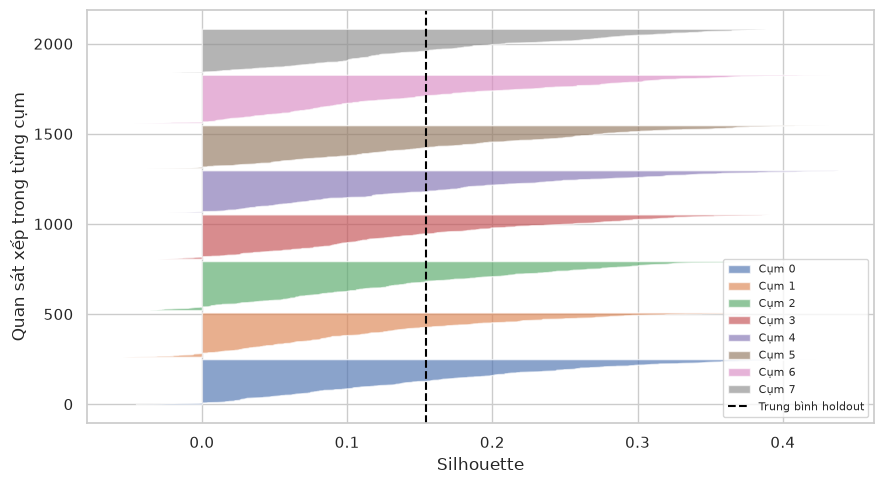

In [3]:
values = silhouette_samples(Z_test[test_eval], reference_labels[test_eval])
plt.figure(figsize=(9, 5))
start = 0
for cluster in sorted(np.unique(reference_labels)):
    within = np.sort(values[reference_labels[test_eval] == cluster])
    end = start + len(within)
    plt.fill_betweenx(np.arange(start, end), 0, within, alpha=.65, label=f"Cụm {cluster}")
    start = end + 12
plt.axvline(values.mean(), color="black", linestyle="--", label="Trung bình holdout")
plt.xlabel("Silhouette"); plt.ylabel("Quan sát xếp trong từng cụm"); plt.legend(fontsize=8)
save_plot("06_holdout_silhouette.png")

Đổi seed lấy mẫu Ward nhưng giữ nguyên train, holdout và k. ARI so sánh hai phân hoạch, có điều chỉnh
ngẫu nhiên và không phụ thuộc số hiệu nhãn. **ARI ở đây đo ổn định, không đo đúng sai với nhãn thật.**

In [4]:
k = selected["Ward_KMeans"]
stability_rows = []
for seed in [7, 21, 84, 123, 2026]:
    si = np.random.default_rng(seed).choice(len(Z_train), len(selection["sample_idx"]), replace=False)
    zz = Z_train[si]
    stree = linkage(zz, method="ward")
    wl = cut_tree(stree, n_clusters=k).ravel()
    trial = KMeans(n_clusters=k, init=centers_from_labels(zz, wl), n_init=1,
                   max_iter=300, random_state=seed).fit(Z_train)
    labels = trial.predict(Z_test)
    stability_rows.append({"seed": seed, "ari_vs_seed42": adjusted_rand_score(reference_labels, labels),
                           **metrics(Z_test, labels, test_eval, test_distances)})
stability = pd.DataFrame(stability_rows)
display(stability)
display(Markdown(f"ARI trung bình **{stability.ari_vs_seed42.mean():.4f}**, "
                 f"thấp nhất **{stability.ari_vs_seed42.min():.4f}**. "
                 "Phân hoạch còn nhạy với mẫu khởi tạo; chưa nên dùng nhãn như quy tắc vận hành cố định."))
stability.to_csv(NBOUT / "stability.csv", index=False)

,seed,ari_vs_seed42,silhouette,davies_bouldin,min_cluster_pct
0,7,0.2814,0.1571,1.4636,11.6273
1,21,0.2612,0.1547,1.4534,10.7781
2,84,0.2755,0.1591,1.4281,11.6648
3,123,0.3958,0.1510,1.4663,11.4025
4,2026,0.3523,0.1596,1.4263,10.7656


ARI trung bình **0.3132**, thấp nhất **0.2612**. Phân hoạch còn nhạy với mẫu khởi tạo; chưa nên dùng nhãn như quy tắc vận hành cố định.

In [5]:
keep = [i for i, feature in enumerate(FEATURES) if feature != "PlayTimeHours"]
alt_sample = Z_train[selection["sample_idx"]][:, keep]
alt_tree = linkage(alt_sample, method="ward")
alt_ward = cut_tree(alt_tree, n_clusters=k).ravel()
alt = KMeans(n_clusters=k, init=centers_from_labels(alt_sample, alt_ward), n_init=1,
             max_iter=300, random_state=SEED).fit(Z_train[:, keep])
alt_labels = alt.predict(Z_test[:, keep])
sensitivity = {"excluded": "PlayTimeHours", "k_fixed": k,
               "ari_vs_main": adjusted_rand_score(reference_labels, alt_labels),
               **metrics(Z_test[:, keep], alt_labels, test_eval,
                         pairwise_distances(Z_test[test_eval][:, keep]))}
display(pd.DataFrame([sensitivity]))
(NBOUT / "feature_sensitivity.json").write_text(json.dumps(sensitivity, indent=2), encoding="utf-8")
joblib.dump({"prep": state["prep"], "model": model, "features": FEATURES,
             "method": "Ward_KMeans", "seed": SEED}, NBOUT / "player_model.joblib")

,excluded,k_fixed,ari_vs_main,silhouette,davies_bouldin,min_cluster_pct
0,PlayTimeHours,8,0.2458,0.225,1.1132,11.6898


['C:\\Bop\\New folder\\gamer_profiling\\outputs\\notebook\\validation_bd40b6e5a2\\modular\\player_model.joblib']

Bỏ PlayTimeHours làm thay đổi không gian từ năm xuống bốn chiều. ARI cho biết gán nhóm thay đổi ra sao;
không dùng Silhouette/DBI ở hai không gian khác nhau để xếp hạng thắng thua trực tiếp.
Silhouette khoảng 0,15 và ARI trung bình khoảng 0,31 cho thấy ranh giới chưa rõ và còn nhạy với mẫu.